In [5]:
import pandas as pd


In [6]:
# Wczytanie danych z pliku CSV
df = pd.read_csv('vgsales.csv')

# Wyświetlenie pierwszych 5 wierszy
print("--- PIERWSZE WIERSZE ---")
print(df.head())

# Podstawowe informacje (liczba wierszy, typy danych, czy są braki - tzw. missing values)
print("\n--- INFORMACJE O DANYCH ---")
print(df.info())

# Statystyki opisowe dla kolumn liczbowych (średnia, min, max, kwartyle)
print("\n--- STATYSTYKI ---")
print(df.describe())

--- PIERWSZE WIERSZE ---
   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  

--- INFORMACJE O DANYCH ---
<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column  

In [7]:
# Sprawdź, ile mamy braków danych w poszczególnych kolumnach
print("Brakujące dane:\n", df.isnull().sum())

# Usuwamy wiersze, które mają puste wartości (np. brak roku wydania)
df_clean = df.dropna().copy()

# Sprawdzamy, ile wierszy zostało
print(f"Liczba wierszy po czyszczeniu: {len(df_clean)}")

Brakujące dane:
 Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64
Liczba wierszy po czyszczeniu: 16291


In [8]:

top_genres = df_clean.groupby('Genre')['Global_Sales'].sum().reset_index()

top_genres = top_genres.sort_values(by='Global_Sales', ascending=False)

print("\n--- TOP 5 GATUNKÓW GIER ---")
print(top_genres.head(5))


--- TOP 5 GATUNKÓW GIER ---
           Genre  Global_Sales
0         Action       1722.84
10        Sports       1309.24
8        Shooter       1026.20
7   Role-Playing        923.83
4       Platform        829.13


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\krzys\AppData\Local\Temp\ipykernel_21828\1866903181.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_5, x='Genre', y='Global_Sales', palette='Blues_d')


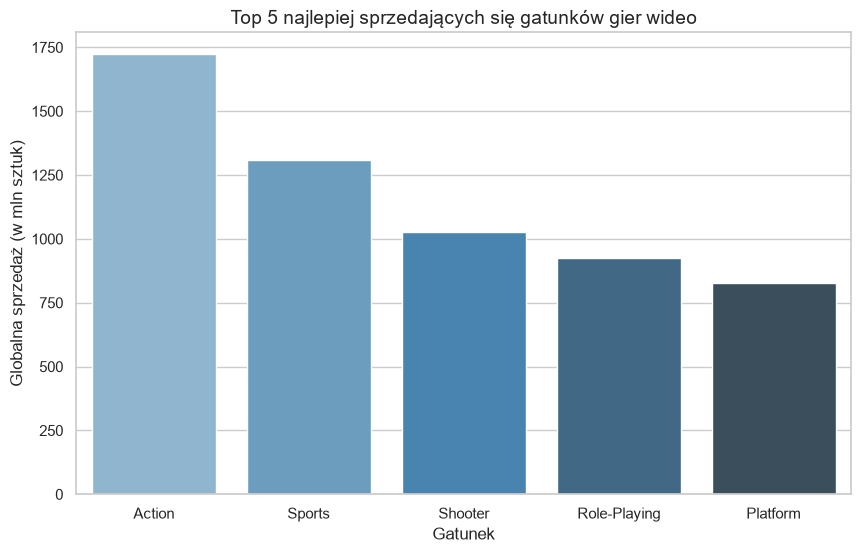

In [11]:
# Ustawienie stylu wykresów
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# Tworzenie wykresu słupkowego
top_5 = top_genres.head(5)
sns.barplot(data=top_5, x='Genre', y='Global_Sales', palette='Blues_d')

# Dodanie etykiet
plt.title('Top 5 najlepiej sprzedających się gatunków gier wideo', fontsize=14)
plt.ylabel('Globalna sprzedaż (w mln sztuk)', fontsize=12)
plt.xlabel('Gatunek', fontsize=12)

# Wyświetlenie wykresu
plt.show()